Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]
Segment bounds: [(0, 12), (12, 19), (19, 34), (34, 49), (49, 63)]


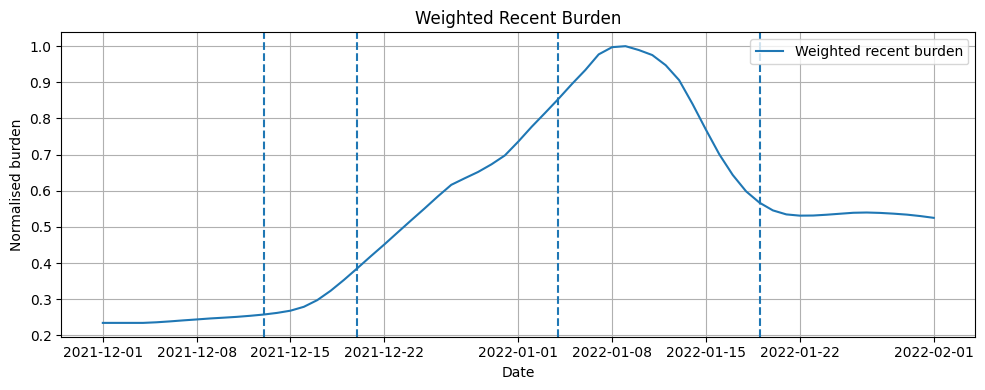


Fitting finished
Success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
rho: 1.1166561598562978
I0: 197113.5714281378
gamma: 0.14285714285714285
MSE: 82150711.20036776
RMSE: 9063.7029519048
log_MSE: 0.005414038703849076

Estimated segment parameters:
Segment 1: beta0 = 0.223324, k = 0.949451
Segment 2: beta0 = 0.286032, k = 0.961378
Segment 3: beta0 = 0.212638, k = 0.120466
Segment 4: beta0 = 0.158863, k = 0.287486
Segment 5: beta0 = 0.238909, k = 0.995728


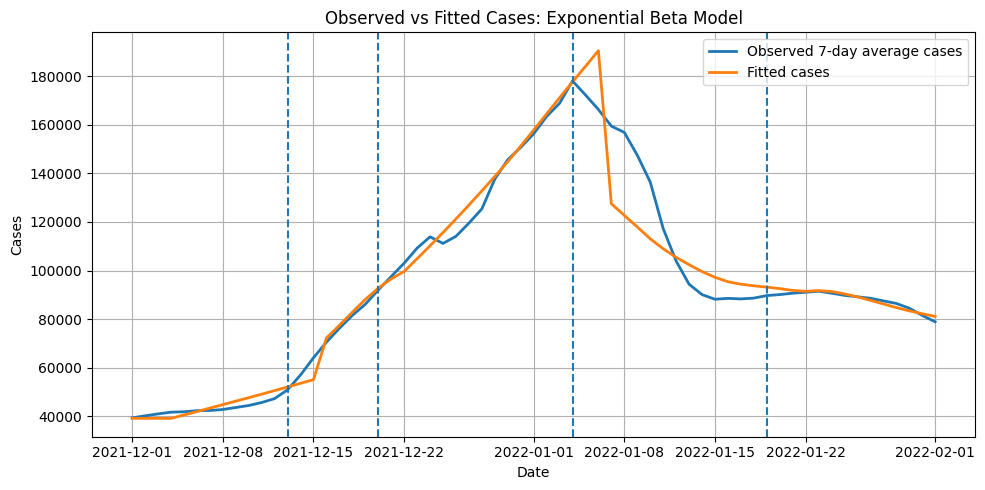

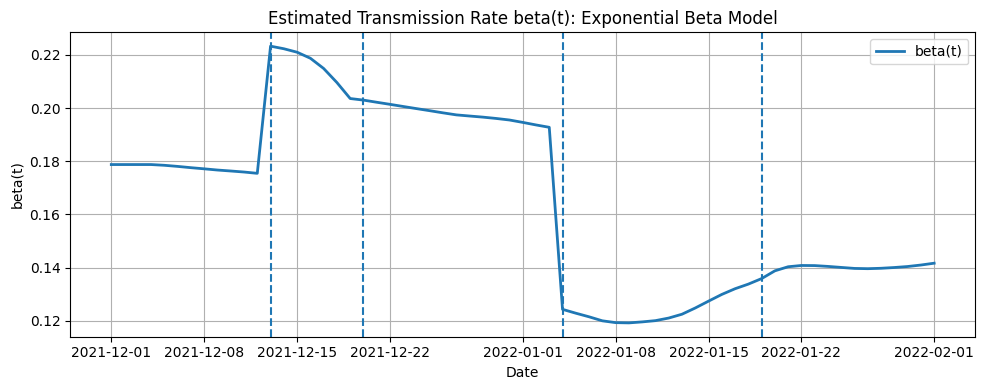


Segment summary:
   segment  start_date    end_date  beta_start  beta_end  beta_mean  \
0        1  2021-12-01  2021-12-12    0.178731  0.175431   0.177536   
1        2  2021-12-13  2021-12-19    0.223267  0.203570   0.216187   
2        3  2021-12-20  2022-01-03    0.202974  0.192744   0.197837   
3        4  2022-01-04  2022-01-18    0.124265  0.133756   0.123845   
4        5  2022-01-19  2022-02-01    0.135836  0.141625   0.139906   

   observed_mean_cases  fitted_mean_cases  model_mean_incidence  
0         42785.380952       43468.880812          42154.194095  
1         69536.081633       68817.166172          78017.566679  
2        127234.695238      128597.259627         130869.047932  
3        125095.752381      122046.277355          92911.682740  
4         87905.071429       88400.065586          76614.265283  


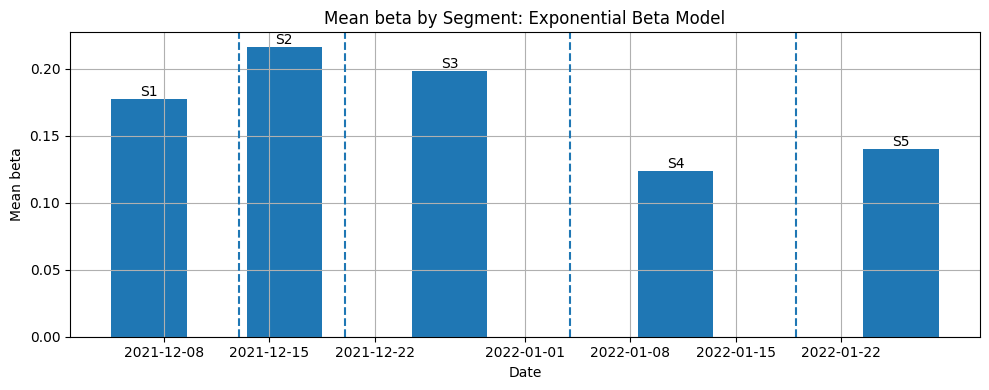


Saved:
../results/exp_beta_fitting_cases.png
../results/exp_beta_fitting_beta.png
../results/exp_beta_segment_summary.csv
../results/exp_beta_fitting_paths.csv


In [3]:
# =========================================================
# Exponential beta fitting only
#
# Purpose:
# Fit the factual behavioural SIR model only.
# No counterfactual experiment is included in this file.
#
# Model:
#   beta_j(t) = beta0_j * exp(-k_j * B(t))
#
# where B(t) is the exponentially weighted recent reported burden.
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =========================================================
# BLOCK 1: data + weighted recent burden
# =========================================================

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"].reset_index(drop=True)
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

# fixed settings
tau = 3
gamma = 1 / 7
N = 67_000_000

# breakpoints
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]
break_indices = [int(np.where(dates == pd.Timestamp(d))[0][0]) for d in break_dates]


def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]


segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

print("Break dates:", break_dates)
print("Break indices:", break_indices)
print("Segment bounds:", segment_bounds)

# delay function

def apply_delay(x, tau):
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y


obs_delayed = apply_delay(obs_cases, tau)

# =========================================================
# Weighted recent burden
# =========================================================

L = 7
lam = 0.75

weights = np.array([lam ** ell for ell in range(L)], dtype=float)
weights = weights / weights.sum()

burden = np.zeros(T)

for t in range(T):
    vals = []
    wts = []

    for ell in range(L):
        idx = t - ell
        if idx >= 0:
            vals.append(obs_delayed[idx])
            wts.append(weights[ell])

    vals = np.array(vals, dtype=float)
    wts = np.array(wts, dtype=float)
    wts = wts / wts.sum()

    burden[t] = np.sum(wts * vals)

# normalize burden to [0, 1]
burden = burden / np.max(burden)

# plot burden
plt.figure(figsize=(10, 4))
plt.plot(dates, burden, label="Weighted recent burden")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")
plt.legend()
plt.title("Weighted Recent Burden")
plt.xlabel("Date")
plt.ylabel("Normalised burden")
plt.grid()
plt.tight_layout()
plt.show()

# =========================================================
# BLOCK 2: exponential beta model
# =========================================================


def get_segment_index(t, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t < b:
            return j
    return len(segment_bounds) - 1


# exponential beta formula:
# beta_j(t) = beta0_j * exp(-k_j * B(t))

def beta_t(t, params):
    j = get_segment_index(t, segment_bounds)
    p = params[j]
    B = burden[t]
    beta = p["beta0"] * np.exp(-p["k"] * B)
    return max(1e-8, beta)


# unpack parameters
# theta = [beta0_1, k_1, beta0_2, k_2, ..., beta0_5, k_5, rho, I0]

def unpack(theta):
    params = []
    pos = 0

    for _ in range(n_seg):
        params.append({
            "beta0": theta[pos],
            "k": theta[pos + 1],
        })
        pos += 2

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0


# =========================================================
# BLOCK 3: discrete-time SIR simulation
# =========================================================


def simulate(theta):
    params, rho, I0 = unpack(theta)

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        b = beta_t(t, params)
        beta_path[t] = b

        incidence[t] = b * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "params": params,
        "rho": rho,
        "I0": I0,
    }


# =========================================================
# BLOCK 4: loss function and optimisation
# =========================================================


def loss(theta):
    try:
        sim = simulate(theta)
        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e10
        if np.any(fitted < 0):
            return 1e10

        return np.mean((np.log(fitted + 1) - np.log(obs_cases + 1)) ** 2)

    except Exception:
        return 1e10


# initial values and bounds
x0 = []
bounds = []

for _ in range(n_seg):
    x0 += [0.25, 1.0]             # beta0_j, k_j
    bounds += [(1e-6, 2.0), (0.0, 20.0)]

x0 += [1.0, obs_cases[0] * 5]     # rho, I0
bounds += [(1e-6, 10.0), (1.0, 5_000_000.0)]

x0 = np.array(x0, dtype=float)

res = minimize(
    loss,
    x0,
    bounds=bounds,
    method="L-BFGS-B",
)

theta_hat = res.x
best = simulate(theta_hat)

# diagnostics
mse = np.mean((best["fitted_cases"] - obs_cases) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(best["fitted_cases"] + 1) - np.log(obs_cases + 1)) ** 2)

print("\nFitting finished")
print("Success:", res.success)
print("Message:", res.message)
print("rho:", best["rho"])
print("I0:", best["I0"])
print("gamma:", gamma)
print("MSE:", mse)
print("RMSE:", rmse)
print("log_MSE:", log_mse)

print("\nEstimated segment parameters:")
for j, p in enumerate(best["params"], start=1):
    print(f"Segment {j}: beta0 = {p['beta0']:.6f}, k = {p['k']:.6f}")

# =========================================================
# BLOCK 5: plots
# =========================================================

beta_path = best["beta_path"]
fitted_cases = best["fitted_cases"]
incidence = best["incidence"]

# observed vs fitted cases
plt.figure(figsize=(10, 5))
plt.plot(dates, obs_cases, label="Observed 7-day average cases", linewidth=2)
plt.plot(dates, fitted_cases, label="Fitted cases", linewidth=2)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Observed vs Fitted Cases: Exponential Beta Model")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/exp_beta_fitting_cases.png", dpi=300, bbox_inches="tight")
plt.show()

# beta(t)
plt.figure(figsize=(10, 4))
plt.plot(dates, beta_path, label="beta(t)", linewidth=2)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Estimated Transmission Rate beta(t): Exponential Beta Model")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/exp_beta_fitting_beta.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# BLOCK 6: segment summary
# =========================================================

summary = []

for j, (a, b) in enumerate(segment_bounds):
    seg_beta = beta_path[a:b]
    seg_obs = obs_cases[a:b]
    seg_fit = fitted_cases[a:b]
    seg_inc = incidence[a:b]

    summary.append({
        "segment": j + 1,
        "start_date": dates.iloc[a].strftime("%Y-%m-%d"),
        "end_date": dates.iloc[b - 1].strftime("%Y-%m-%d"),
        "beta_start": float(seg_beta[0]),
        "beta_end": float(seg_beta[-1]),
        "beta_mean": float(np.mean(seg_beta)),
        "observed_mean_cases": float(np.mean(seg_obs)),
        "fitted_mean_cases": float(np.mean(seg_fit)),
        "model_mean_incidence": float(np.mean(seg_inc)),
    })

seg_df = pd.DataFrame(summary)
print("\nSegment summary:")
print(seg_df)

seg_df.to_csv("../results/exp_beta_segment_summary.csv", index=False)

# mean beta by segment
mid_dates = [dates.iloc[(a + b) // 2] for (a, b) in segment_bounds]

plt.figure(figsize=(10, 4))
plt.bar(mid_dates, seg_df["beta_mean"], width=5)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

for i, row in seg_df.iterrows():
    plt.text(
        mid_dates[i],
        row["beta_mean"],
        f"S{int(row['segment'])}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.title("Mean beta by Segment: Exponential Beta Model")
plt.xlabel("Date")
plt.ylabel("Mean beta")
plt.grid()
plt.tight_layout()
plt.savefig("../results/exp_beta_segment_mean.png", dpi=300, bbox_inches="tight")
plt.show()

# save full paths
paths_df = pd.DataFrame({
    "date": dates,
    "observed_cases": obs_cases,
    "burden": burden,
    "fitted_cases": fitted_cases,
    "beta_path": beta_path,
    "incidence": incidence,
})

paths_df.to_csv("../results/exp_beta_fitting_paths.csv", index=False)

print("\nSaved:")
print("../results/exp_beta_fitting_cases.png")
print("../results/exp_beta_fitting_beta.png")
print("../results/exp_beta_segment_summary.csv")
print("../results/exp_beta_fitting_paths.csv")


Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]
Segment bounds: [(0, 12), (12, 19), (19, 34), (34, 49), (49, 63)]


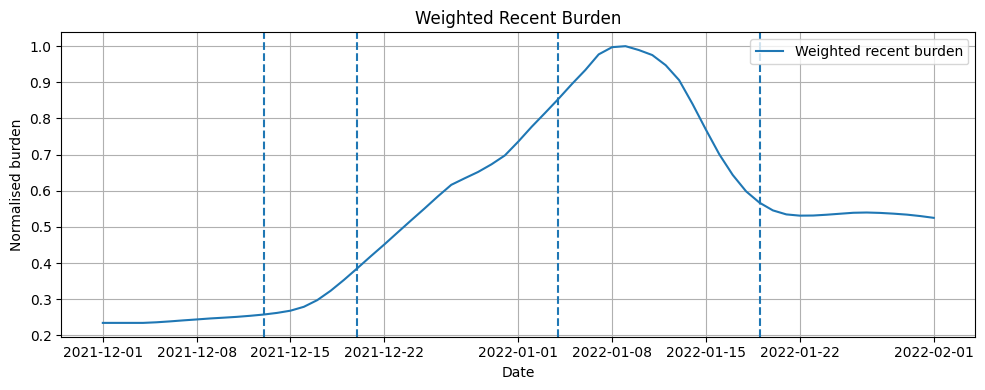


Fitting finished
Success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
rho: 1.1368957016720747
I0: 197113.57143155692
gamma: 0.14285714285714285
MSE: 83493485.55679154
RMSE: 9137.476979822797
log_MSE: 0.0053498533475630035

Estimated segment parameters:
Segment 1: beta0 = 0.280676, k = 0.644956, h = 0.022370
Segment 2: beta0 = 0.375899, k = 0.847760, h = 0.041378
Segment 3: beta0 = 0.313969, k = 0.691865, h = 0.100160
Segment 4: beta0 = 0.176359, k = 1.594654, h = 2.335526
Segment 5: beta0 = 0.229874, k = 1.026485, h = 0.316671


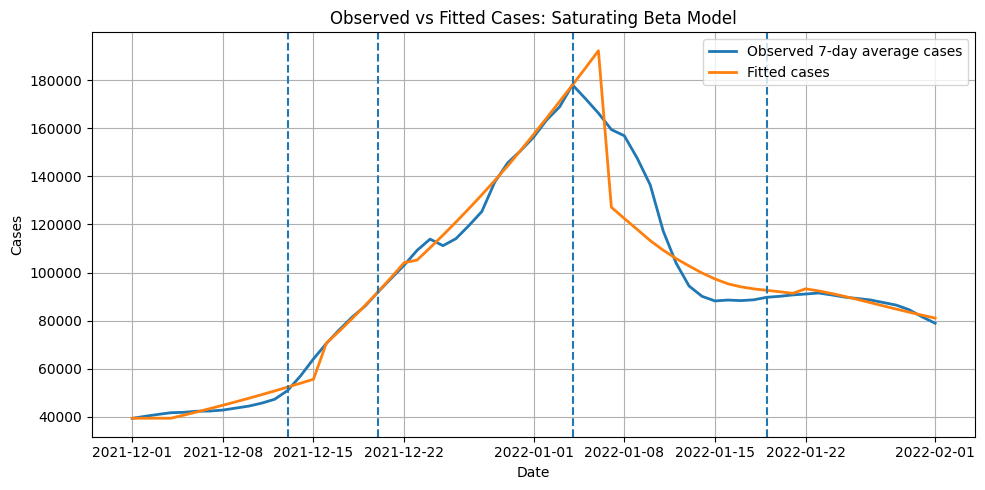

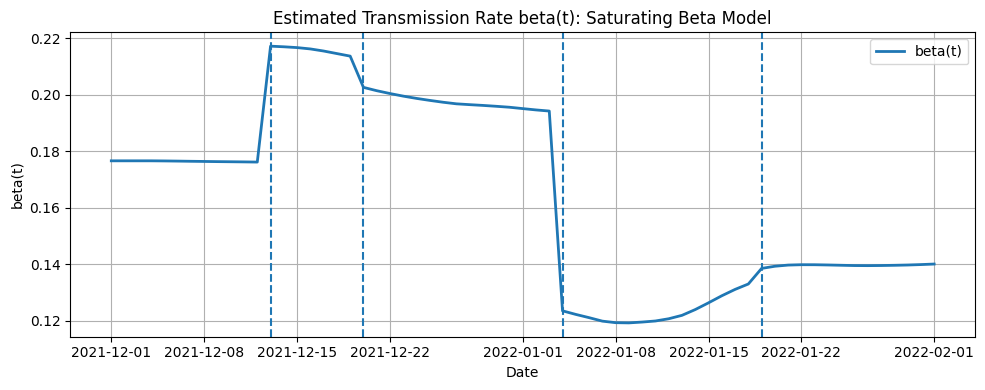


Segment summary:
   segment  start_date    end_date  beta_start  beta_end  beta_mean  \
0        1  2021-12-01  2021-12-12    0.176658  0.176216   0.176494   
1        2  2021-12-13  2021-12-19    0.217224  0.213703   0.215858   
2        3  2021-12-20  2022-01-03    0.202646  0.194267   0.197569   
3        4  2022-01-04  2022-01-18    0.123577  0.133078   0.123444   
4        5  2022-01-19  2022-02-01    0.138590  0.140137   0.139669   

   observed_mean_cases  fitted_mean_cases  model_mean_incidence  
0         42785.380952       43600.227948          41551.842286  
1         69536.081633       67993.553457          76403.428618  
2        127234.695238      128756.046225         128560.228136  
3        125095.752381      122251.761311          91158.595301  
4         87905.071429       88379.511370          75240.530248  


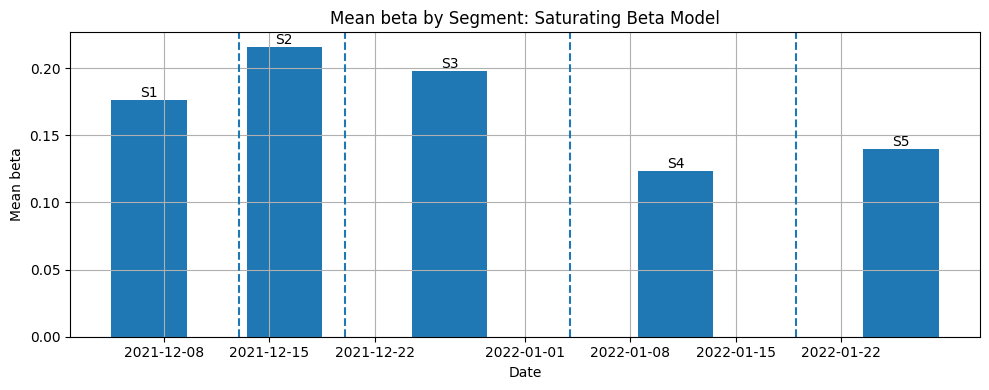


Saved:
../results/sat_beta_fitting_cases.png
../results/sat_beta_fitting_beta.png
../results/sat_beta_segment_mean.png
../results/sat_beta_segment_summary.csv
../results/sat_beta_fitting_paths.csv


In [4]:
# =========================================================
# Saturating beta fitting only
#
# Purpose:
# Fit the factual behavioural SIR model only.
# No counterfactual experiment is included in this file.
#
# Model:
#   beta_j(t) = beta0_j / (1 + k_j * B(t) / (h_j + B(t)))
#
# where B(t) is the exponentially weighted recent reported burden.
# =========================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

os.makedirs("../results", exist_ok=True)

# =========================================================
# BLOCK 1: data + weighted recent burden
# =========================================================

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"].reset_index(drop=True)
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

# fixed settings
tau = 3
gamma = 1 / 7
N = 67_000_000

# breakpoints
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]
break_indices = [int(np.where(dates == pd.Timestamp(d))[0][0]) for d in break_dates]


def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]


segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

print("Break dates:", break_dates)
print("Break indices:", break_indices)
print("Segment bounds:", segment_bounds)

# delay function

def apply_delay(x, tau):
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y


obs_delayed = apply_delay(obs_cases, tau)

# =========================================================
# Weighted recent burden
# =========================================================

L = 7
lam = 0.75

weights = np.array([lam ** ell for ell in range(L)], dtype=float)
weights = weights / weights.sum()

burden = np.zeros(T)

for t in range(T):
    vals = []
    wts = []

    for ell in range(L):
        idx = t - ell
        if idx >= 0:
            vals.append(obs_delayed[idx])
            wts.append(weights[ell])

    vals = np.array(vals, dtype=float)
    wts = np.array(wts, dtype=float)
    wts = wts / wts.sum()

    burden[t] = np.sum(wts * vals)

# normalize burden to [0, 1]
max_burden = np.max(burden)
if max_burden > 0:
    burden = burden / max_burden
else:
    burden = burden

# plot burden
plt.figure(figsize=(10, 4))
plt.plot(dates, burden, label="Weighted recent burden")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")
plt.legend()
plt.title("Weighted Recent Burden")
plt.xlabel("Date")
plt.ylabel("Normalised burden")
plt.grid()
plt.tight_layout()
plt.show()

# =========================================================
# BLOCK 2: saturating beta model
# =========================================================


def get_segment_index(t, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t < b:
            return j
    return len(segment_bounds) - 1


# saturating beta formula:
# beta_j(t) = beta0_j / (1 + k_j * B(t) / (h_j + B(t)))

def beta_t(t, params):
    j = get_segment_index(t, segment_bounds)
    p = params[j]

    B = burden[t]
    beta0 = p["beta0"]
    k = p["k"]
    h = p["h"]

    beta = beta0 / (1.0 + (k * B) / (h + B))

    return max(1e-8, beta)


# unpack parameters
# theta = [
#   beta0_1, k_1, h_1,
#   beta0_2, k_2, h_2,
#   ...
#   beta0_5, k_5, h_5,
#   rho, I0
# ]

def unpack(theta):
    params = []
    pos = 0

    for _ in range(n_seg):
        params.append({
            "beta0": theta[pos],
            "k": theta[pos + 1],
            "h": theta[pos + 2],
        })
        pos += 3

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0


# =========================================================
# BLOCK 3: discrete-time SIR simulation
# =========================================================


def simulate(theta):
    params, rho, I0 = unpack(theta)

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        b = beta_t(t, params)
        beta_path[t] = b

        incidence[t] = b * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "params": params,
        "rho": rho,
        "I0": I0,
    }


# =========================================================
# BLOCK 4: loss function and optimisation
# =========================================================


def loss(theta):
    try:
        sim = simulate(theta)
        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e10
        if np.any(fitted < 0):
            return 1e10

        return np.mean((np.log(fitted + 1) - np.log(obs_cases + 1)) ** 2)

    except Exception:
        return 1e10


# initial values and bounds
x0 = []
bounds = []

for _ in range(n_seg):
    # beta0_j, k_j, h_j
    x0 += [0.25, 1.0, 0.2]

    bounds += [
        (1e-6, 2.0),      # beta0_j
        (0.0, 50.0),      # k_j
        (1e-6, 5.0),      # h_j
    ]

x0 += [1.0, obs_cases[0] * 5]     # rho, I0
bounds += [
    (1e-6, 10.0),         # rho
    (1.0, 5_000_000.0),   # I0
]

x0 = np.array(x0, dtype=float)

res = minimize(
    loss,
    x0,
    bounds=bounds,
    method="L-BFGS-B",
)

theta_hat = res.x
best = simulate(theta_hat)

# diagnostics
mse = np.mean((best["fitted_cases"] - obs_cases) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(best["fitted_cases"] + 1) - np.log(obs_cases + 1)) ** 2)

print("\nFitting finished")
print("Success:", res.success)
print("Message:", res.message)
print("rho:", best["rho"])
print("I0:", best["I0"])
print("gamma:", gamma)
print("MSE:", mse)
print("RMSE:", rmse)
print("log_MSE:", log_mse)

print("\nEstimated segment parameters:")
for j, p in enumerate(best["params"], start=1):
    print(
        f"Segment {j}: "
        f"beta0 = {p['beta0']:.6f}, "
        f"k = {p['k']:.6f}, "
        f"h = {p['h']:.6f}"
    )


# =========================================================
# BLOCK 5: plots
# =========================================================

beta_path = best["beta_path"]
fitted_cases = best["fitted_cases"]
incidence = best["incidence"]

# observed vs fitted cases
plt.figure(figsize=(10, 5))
plt.plot(dates, obs_cases, label="Observed 7-day average cases", linewidth=2)
plt.plot(dates, fitted_cases, label="Fitted cases", linewidth=2)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Observed vs Fitted Cases: Saturating Beta Model")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_beta_fitting_cases.png", dpi=300, bbox_inches="tight")
plt.show()

# beta(t)
plt.figure(figsize=(10, 4))
plt.plot(dates, beta_path, label="beta(t)", linewidth=2)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Estimated Transmission Rate beta(t): Saturating Beta Model")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_beta_fitting_beta.png", dpi=300, bbox_inches="tight")
plt.show()


# =========================================================
# BLOCK 6: segment summary
# =========================================================

summary = []

for j, (a, b) in enumerate(segment_bounds):
    seg_beta = beta_path[a:b]
    seg_obs = obs_cases[a:b]
    seg_fit = fitted_cases[a:b]
    seg_inc = incidence[a:b]

    summary.append({
        "segment": j + 1,
        "start_date": dates.iloc[a].strftime("%Y-%m-%d"),
        "end_date": dates.iloc[b - 1].strftime("%Y-%m-%d"),
        "beta_start": float(seg_beta[0]),
        "beta_end": float(seg_beta[-1]),
        "beta_mean": float(np.mean(seg_beta)),
        "observed_mean_cases": float(np.mean(seg_obs)),
        "fitted_mean_cases": float(np.mean(seg_fit)),
        "model_mean_incidence": float(np.mean(seg_inc)),
    })

seg_df = pd.DataFrame(summary)

print("\nSegment summary:")
print(seg_df)

seg_df.to_csv("../results/sat_beta_segment_summary.csv", index=False)

# mean beta by segment
mid_dates = [dates.iloc[(a + b) // 2] for (a, b) in segment_bounds]

plt.figure(figsize=(10, 4))
plt.bar(mid_dates, seg_df["beta_mean"], width=5)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

for i, row in seg_df.iterrows():
    plt.text(
        mid_dates[i],
        row["beta_mean"],
        f"S{int(row['segment'])}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.title("Mean beta by Segment: Saturating Beta Model")
plt.xlabel("Date")
plt.ylabel("Mean beta")
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_beta_segment_mean.png", dpi=300, bbox_inches="tight")
plt.show()


# =========================================================
# BLOCK 7: save full paths
# =========================================================

paths_df = pd.DataFrame({
    "date": dates,
    "observed_cases": obs_cases,
    "burden": burden,
    "fitted_cases": fitted_cases,
    "beta_path": beta_path,
    "incidence": incidence,
})

paths_df.to_csv("../results/sat_beta_fitting_paths.csv", index=False)

print("\nSaved:")
print("../results/sat_beta_fitting_cases.png")
print("../results/sat_beta_fitting_beta.png")
print("../results/sat_beta_segment_mean.png")
print("../results/sat_beta_segment_summary.csv")
print("../results/sat_beta_fitting_paths.csv")

Bootstrap 25/300 finished. Success: True
Bootstrap 50/300 finished. Success: True
Bootstrap 75/300 finished. Success: True
Bootstrap 100/300 finished. Success: True
Bootstrap 125/300 finished. Success: True
Bootstrap 150/300 finished. Success: True
Bootstrap 175/300 finished. Success: True
Bootstrap 200/300 finished. Success: True
Bootstrap 225/300 finished. Success: True
Bootstrap 250/300 finished. Success: True
Bootstrap 275/300 finished. Success: True
Bootstrap 300/300 finished. Success: True

Bootstrap finished
Successful stored runs: 300
Optimisation success rate: 0.9966666666666667


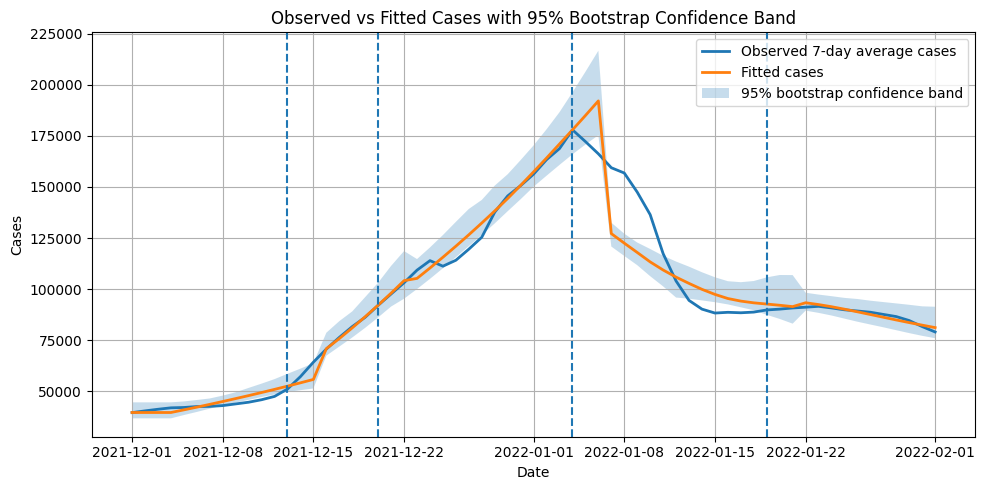

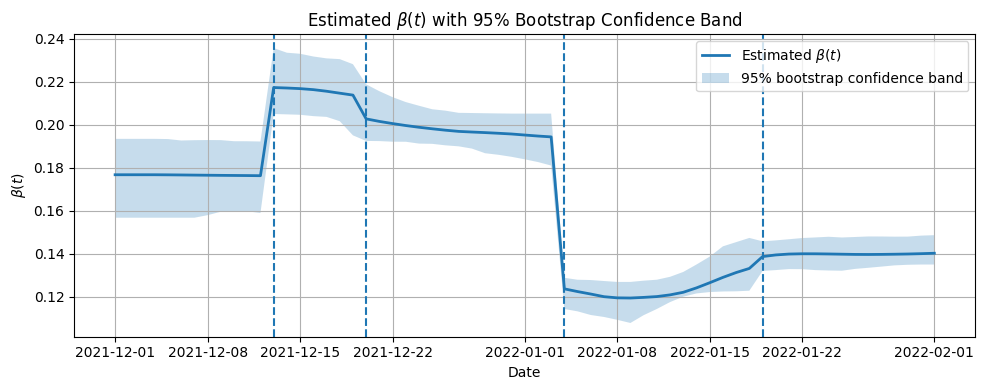


Saved bootstrap CI results:
../results/sat_beta_fitting_cases_bootstrap_CI.png
../results/sat_beta_beta_bootstrap_CI.png
../results/sat_beta_bootstrap_CI_paths.csv

Parameter bootstrap summary:
   parameter       estimate       lower_95       upper_95  bootstrap_mean  \
0    beta0_1       0.280676       0.188429       0.535278        0.286949   
1        k_1       0.644956       0.489683      10.506760        1.671199   
2        h_1       0.022370       0.000001       3.742015        0.463275   
3    beta0_2       0.375899       0.234843       0.676001        0.376451   
4        k_2       0.847760       0.749455       6.205054        1.578793   
5        h_2       0.041378       0.000001       2.792833        0.466683   
6    beta0_3       0.313969       0.208115       0.354958        0.297737   
7        k_3       0.691865       0.043447       3.027951        0.894100   
8        h_3       0.100160       0.000001       5.000000        0.905313   
9    beta0_4       0.176359       0

In [5]:
# =========================================================
# BLOCK 8: Moving-block residual bootstrap confidence interval
#
# Purpose:
# Add 95% bootstrap confidence bands for:
#   1. fitted cases
#   2. beta(t)
#
# Method:
#   moving-block residual bootstrap on log scale
#
# Important:
#   This code assumes that your original fitting code has already run,
#   so theta_hat, best, obs_cases, dates, break_dates, bounds, etc. exist.
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import os

os.makedirs("../results", exist_ok=True)


# ---------------------------------------------------------
# 1. Recompute burden from any case series
# ---------------------------------------------------------

def compute_burden_from_cases(cases, tau=3, L=7, lam=0.75):
    """
    Compute weighted recent burden from a given case series.
    This is needed because each bootstrap pseudo-dataset has its own cases.
    """
    cases = np.asarray(cases, dtype=float)
    T_local = len(cases)

    delayed_cases = apply_delay(cases, tau)

    weights = np.array([lam ** ell for ell in range(L)], dtype=float)
    weights = weights / weights.sum()

    B = np.zeros(T_local)

    for t in range(T_local):
        vals = []
        wts = []

        for ell in range(L):
            idx = t - ell
            if idx >= 0:
                vals.append(delayed_cases[idx])
                wts.append(weights[ell])

        vals = np.array(vals, dtype=float)
        wts = np.array(wts, dtype=float)
        wts = wts / wts.sum()

        B[t] = np.sum(wts * vals)

    max_B = np.max(B)
    if max_B > 0:
        B = B / max_B

    return B


# ---------------------------------------------------------
# 2. Bootstrap version of beta(t), simulate, and loss
# ---------------------------------------------------------

def beta_t_given_burden(t, params, burden_in):
    """
    Same saturating beta formula as your original code,
    but now burden is passed in explicitly.
    """
    j = get_segment_index(t, segment_bounds)
    p = params[j]

    B = burden_in[t]
    beta0 = p["beta0"]
    k = p["k"]
    h = p["h"]

    beta = beta0 / (1.0 + (k * B) / (h + B))

    return max(1e-8, beta)


def simulate_given_burden(theta, burden_in):
    """
    Same SIR simulation as your original simulate(theta),
    but using a supplied burden series.
    """
    params, rho, I0 = unpack(theta)

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        b = beta_t_given_burden(t, params, burden_in)
        beta_path[t] = b

        incidence[t] = b * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "params": params,
        "rho": rho,
        "I0": I0,
    }


def loss_for_cases(theta, cases_in):
    """
    Loss function for a given case series.
    This is used when refitting each bootstrap pseudo-dataset.
    """
    try:
        burden_in = compute_burden_from_cases(cases_in, tau=tau, L=L, lam=lam)
        sim = simulate_given_burden(theta, burden_in)
        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e10

        if np.any(fitted < 0):
            return 1e10

        return np.mean((np.log(fitted + 1) - np.log(cases_in + 1)) ** 2)

    except Exception:
        return 1e10


def fit_model_to_cases(cases_in, init_theta):
    """
    Refit model to a bootstrap pseudo-dataset.
    Uses theta_hat as a warm start.
    """
    res_b = minimize(
        lambda th: loss_for_cases(th, cases_in),
        init_theta,
        bounds=bounds,
        method="L-BFGS-B",
        options={
            "maxiter": 800,
            "ftol": 1e-9,
        }
    )

    theta_b = res_b.x
    burden_b = compute_burden_from_cases(cases_in, tau=tau, L=L, lam=lam)
    sim_b = simulate_given_burden(theta_b, burden_b)

    return theta_b, sim_b, res_b


# ---------------------------------------------------------
# 3. Moving-block residual resampling
# ---------------------------------------------------------

def moving_block_resample(residuals, block_len=7):
    """
    Moving-block bootstrap for time-series residuals.
    It samples consecutive residual blocks and joins them together.
    """
    residuals = np.asarray(residuals, dtype=float)
    n = len(residuals)

    sampled = []

    while len(sampled) < n:
        start = np.random.randint(0, n - block_len + 1)
        block = residuals[start:start + block_len]
        sampled.extend(block)

    return np.array(sampled[:n])


# ---------------------------------------------------------
# 4. Main bootstrap function
# ---------------------------------------------------------

def run_moving_block_residual_bootstrap(
    n_boot=300,
    block_len=7,
    seed=123,
    jitter_scale=0.03
):
    """
    Run moving-block residual bootstrap.

    n_boot:
        Number of bootstrap refits.
        Use 200 for quick testing, 500 for final version.

    block_len:
        Block length. 7 is natural here because the data use 7-day moving average.

    jitter_scale:
        Small random perturbation to initial theta for each bootstrap refit.
        This helps avoid always returning the same local optimum.
    """

    rng = np.random.default_rng(seed)

    fitted_original = best["fitted_cases"]
    beta_original = best["beta_path"]

    # log residuals from original fit
    log_resid = np.log(obs_cases + 1) - np.log(fitted_original + 1)

    # centre residuals
    log_resid = log_resid - np.mean(log_resid)

    fitted_boot = []
    beta_boot = []
    theta_boot = []
    success_flags = []

    for b in range(n_boot):
        try:
            # resample residual blocks
            resid_star = moving_block_resample(log_resid, block_len=block_len)

            # generate pseudo-data on log scale
            log_cases_star = np.log(fitted_original + 1) + resid_star
            cases_star = np.exp(log_cases_star) - 1
            cases_star = np.maximum(cases_star, 0.0)

            # warm start with small multiplicative jitter
            init_theta = theta_hat.copy()
            jitter = rng.normal(loc=0.0, scale=jitter_scale, size=len(init_theta))
            init_theta = init_theta * (1.0 + jitter)

            # keep initial theta inside bounds
            for i, (lo, hi) in enumerate(bounds):
                init_theta[i] = np.clip(init_theta[i], lo, hi)

            # refit model
            theta_b, sim_b, res_b = fit_model_to_cases(cases_star, init_theta)

            fitted_boot.append(sim_b["fitted_cases"])
            beta_boot.append(sim_b["beta_path"])
            theta_boot.append(theta_b)
            success_flags.append(res_b.success)

            if (b + 1) % 25 == 0:
                print(f"Bootstrap {b + 1}/{n_boot} finished. Success: {res_b.success}")

        except Exception as e:
            print(f"Bootstrap {b + 1} failed: {e}")
            continue

    fitted_boot = np.array(fitted_boot)
    beta_boot = np.array(beta_boot)
    theta_boot = np.array(theta_boot)

    print("\nBootstrap finished")
    print("Successful stored runs:", fitted_boot.shape[0])
    print("Optimisation success rate:", np.mean(success_flags) if len(success_flags) > 0 else np.nan)

    if fitted_boot.shape[0] < 30:
        print("WARNING: fewer than 30 successful bootstrap runs. Increase n_boot or check optimisation.")

    # pointwise 95% confidence bands
    fitted_lower = np.percentile(fitted_boot, 2.5, axis=0)
    fitted_upper = np.percentile(fitted_boot, 97.5, axis=0)

    beta_lower = np.percentile(beta_boot, 2.5, axis=0)
    beta_upper = np.percentile(beta_boot, 97.5, axis=0)

    return {
        "fitted_original": fitted_original,
        "beta_original": beta_original,
        "fitted_boot": fitted_boot,
        "beta_boot": beta_boot,
        "theta_boot": theta_boot,
        "fitted_lower": fitted_lower,
        "fitted_upper": fitted_upper,
        "beta_lower": beta_lower,
        "beta_upper": beta_upper,
        "success_flags": success_flags,
    }


# ---------------------------------------------------------
# 5. Run bootstrap
# ---------------------------------------------------------

boot = run_moving_block_residual_bootstrap(
    n_boot=300,       # use 100 first for testing; use 300 or 500 for final result
    block_len=7,
    seed=123,
    jitter_scale=0.03
)


# ---------------------------------------------------------
# 6. Plot fitted cases with 95% bootstrap confidence band
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    dates,
    obs_cases,
    label="Observed 7-day average cases",
    linewidth=2
)

plt.plot(
    dates,
    boot["fitted_original"],
    label="Fitted cases",
    linewidth=2
)

plt.fill_between(
    dates,
    boot["fitted_lower"],
    boot["fitted_upper"],
    alpha=0.25,
    label="95% bootstrap confidence band"
)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Observed vs Fitted Cases with 95% Bootstrap Confidence Band")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_beta_fitting_cases_bootstrap_CI.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------------------------------------------------
# 7. Plot beta(t) with 95% bootstrap confidence band
# ---------------------------------------------------------

plt.figure(figsize=(10, 4))

plt.plot(
    dates,
    boot["beta_original"],
    label=r"Estimated $\beta(t)$",
    linewidth=2
)

plt.fill_between(
    dates,
    boot["beta_lower"],
    boot["beta_upper"],
    alpha=0.25,
    label="95% bootstrap confidence band"
)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title(r"Estimated $\beta(t)$ with 95% Bootstrap Confidence Band")
plt.xlabel("Date")
plt.ylabel(r"$\beta(t)$")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_beta_beta_bootstrap_CI.png", dpi=300, bbox_inches="tight")
plt.show()


# ---------------------------------------------------------
# 8. Save bootstrap confidence interval paths
# ---------------------------------------------------------

ci_df = pd.DataFrame({
    "date": dates,
    "observed_cases": obs_cases,
    "fitted_cases": boot["fitted_original"],
    "fitted_lower_95": boot["fitted_lower"],
    "fitted_upper_95": boot["fitted_upper"],
    "beta_path": boot["beta_original"],
    "beta_lower_95": boot["beta_lower"],
    "beta_upper_95": boot["beta_upper"],
})

ci_df.to_csv("../results/sat_beta_bootstrap_CI_paths.csv", index=False)

print("\nSaved bootstrap CI results:")
print("../results/sat_beta_fitting_cases_bootstrap_CI.png")
print("../results/sat_beta_beta_bootstrap_CI.png")
print("../results/sat_beta_bootstrap_CI_paths.csv")


# ---------------------------------------------------------
# 9. Optional: parameter uncertainty table
# ---------------------------------------------------------

def theta_names(n_seg):
    names = []
    for j in range(1, n_seg + 1):
        names += [
            f"beta0_{j}",
            f"k_{j}",
            f"h_{j}",
        ]
    names += ["rho", "I0"]
    return names


if boot["theta_boot"].shape[0] > 0:
    param_names = theta_names(n_seg)

    param_summary = pd.DataFrame({
        "parameter": param_names,
        "estimate": theta_hat,
        "lower_95": np.percentile(boot["theta_boot"], 2.5, axis=0),
        "upper_95": np.percentile(boot["theta_boot"], 97.5, axis=0),
        "bootstrap_mean": np.mean(boot["theta_boot"], axis=0),
        "bootstrap_sd": np.std(boot["theta_boot"], axis=0),
    })

    param_summary.to_csv("../results/sat_beta_bootstrap_parameter_summary.csv", index=False)

    print("\nParameter bootstrap summary:")
    print(param_summary)

    print("\nSaved:")
    print("../results/sat_beta_bootstrap_parameter_summary.csv")

In [7]:
import numpy as np
import pandas as pd

# observed and fitted cases
y_obs = np.asarray(obs_cases, dtype=float)
y_fit = np.asarray(boot["fitted_original"], dtype=float)

# confidence bands for fitted cases
lower = np.asarray(boot["fitted_lower"], dtype=float)
upper = np.asarray(boot["fitted_upper"], dtype=float)

# residuals
resid = y_obs - y_fit
log_resid = np.log(y_obs + 1) - np.log(y_fit + 1)

# fit quality metrics
mse = np.mean(resid ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(resid))
log_mse = np.mean(log_resid ** 2)
corr = np.corrcoef(y_obs, y_fit)[0, 1]

# R-squared style measure
ss_res = np.sum((y_obs - y_fit) ** 2)
ss_tot = np.sum((y_obs - np.mean(y_obs)) ** 2)
r2 = 1 - ss_res / ss_tot

# CI width summary
ci_width = upper - lower
mean_ci_width = np.mean(ci_width)
median_ci_width = np.median(ci_width)

# relative CI width compared with fitted cases
relative_ci_width = ci_width / np.maximum(y_fit, 1)
mean_relative_ci_width = np.mean(relative_ci_width)
median_relative_ci_width = np.median(relative_ci_width)

# descriptive: percentage of observed data inside the fitted-case CI band
# This is NOT formal coverage, but useful as a diagnostic.
inside_band = np.mean((y_obs >= lower) & (y_obs <= upper)) * 100

fit_summary = pd.DataFrame({
    "Quantity": [
        "MSE",
        "RMSE",
        "MAE",
        "Log-MSE",
        "Correlation between observed and fitted cases",
        "R-squared style measure",
        "Mean CI width",
        "Median CI width",
        "Mean relative CI width",
        "Median relative CI width",
        "Observed points inside 95% fitted-case band (%)",
        "Bootstrap replications",
        "Optimisation success rate (%)"
    ],
    "Value": [
        mse,
        rmse,
        mae,
        log_mse,
        corr,
        r2,
        mean_ci_width,
        median_ci_width,
        mean_relative_ci_width,
        median_relative_ci_width,
        inside_band,
        boot["fitted_boot"].shape[0],
        np.mean(boot["success_flags"]) * 100
    ]
})

print(fit_summary)

fit_summary.to_csv("../results/bootstrap_fit_quality_summary.csv", index=False)

                                           Quantity         Value
0                                               MSE  8.349349e+07
1                                              RMSE  9.137477e+03
2                                               MAE  4.876592e+03
3                                           Log-MSE  5.349853e-03
4     Correlation between observed and fitted cases  9.719319e-01
5                           R-squared style measure  9.443475e-01
6                                     Mean CI width  1.438428e+04
7                                   Median CI width  1.313992e+04
8                            Mean relative CI width  1.526434e-01
9                          Median relative CI width  1.434676e-01
10  Observed points inside 95% fitted-case band (%)  6.666667e+01
11                           Bootstrap replications  3.000000e+02
12                    Optimisation success rate (%)  9.966667e+01
